In [2]:
import pandas as pd
import pyodbc
import csv
import numpy as np

In [2]:
# 1. Extract Data

In [3]:
source_data = pd.read_csv('C:/Users/AS72180/OneDrive - ETS/Documents/ETS Hiver2024/ProjectMTI820/Amazon Sale Report.csv',
                        dtype={"fulfilled-by": str, "Unnamed: 22": str}, 
                        parse_dates=["Date"], date_format='%m-%d-%y')
source_data.drop(columns=["Unnamed: 22"], inplace=True)
source_data.drop(columns=["index"], inplace=True)

In [4]:
source_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128975 non-null  object        
 1   Date                128975 non-null  datetime64[ns]
 2   Status              128975 non-null  object        
 3   Fulfilment          128975 non-null  object        
 4   Sales Channel       128975 non-null  object        
 5   ship-service-level  128975 non-null  object        
 6   Style               128975 non-null  object        
 7   SKU                 128975 non-null  object        
 8   Category            128975 non-null  object        
 9   Size                128975 non-null  object        
 10  ASIN                128975 non-null  object        
 11  Courier Status      122103 non-null  object        
 12  Qty                 128975 non-null  int64         
 13  currency            121180 no

In [5]:
# 2. Transform Data
# Clean data, handle missing values, etc.

In [6]:
# Define a dictionary to map old column names to new column names
column_mapping = {
    'Order ID' : 'Order_ID' ,
    'Sales Channel' : 'Sales_Channel' ,
    'ship-service-level' : 'ship_service_level', 
    'Courier Status' : 'Courier_Status', 
    'ship-city' : 'ship_city',
    'ship-state' : 'ship_state',
    'ship-postal-code' : 'ship_postal_code',
    'ship-country' : 'ship_country',  
    'promotion-ids' : 'promotion_ids', 
    'fulfilled-by': 'fulfilled_by',
}

# Rename the columns
source_data.rename(columns=column_mapping, inplace=True)

# Print the DataFrame to verify the changes
print(source_data.head())

              Order_ID       Date                        Status Fulfilment  \
0  405-8078784-5731545 2022-04-30                     Cancelled   Merchant   
1  171-9198151-1101146 2022-04-30  Shipped - Delivered to Buyer   Merchant   
2  404-0687676-7273146 2022-04-30                       Shipped     Amazon   
3  403-9615377-8133951 2022-04-30                     Cancelled   Merchant   
4  407-1069790-7240320 2022-04-30                       Shipped     Amazon   

  Sales Channel  ship_service_level    Style              SKU       Category  \
0      Amazon.in           Standard   SET389   SET389-KR-NP-S            Set   
1      Amazon.in           Standard  JNE3781  JNE3781-KR-XXXL          kurta   
2      Amazon.in          Expedited  JNE3371    JNE3371-KR-XL          kurta   
3      Amazon.in           Standard    J0341       J0341-DR-L  Western Dress   
4      Amazon.in          Expedited  JNE3671  JNE3671-TU-XXXL            Top   

  Size  ... Qty currency  Amount    ship_city   sh

In [7]:
# Check for null values
null_values = source_data.isnull()

# Count null values in each column
null_counts = null_values.sum()

# Check if there are any null values in the DataFrame
if null_counts.any():
    print("DataFrame contains null values.")
    # Print the count of null values in each column
    print("Null value counts per column:")
    print(null_counts)
else:
    print("DataFrame does not contain null values.")

DataFrame contains null values.
Null value counts per column:
Order_ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship_service_level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier_Status         6872
Qty                       0
currency               7795
Amount                 7795
ship_city                33
ship_state               33
ship_postal_code         33
ship_country             33
promotion_ids         49153
B2B                       0
fulfilled_by          89698
dtype: int64


In [8]:
# Removing Null Values
source_data.dropna(subset=['Amount','ship_postal_code', 'ship_state', 'ship_city'],inplace=True)

In [9]:
source_data.isnull().sum()

Order_ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship_service_level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier_Status         5133
Qty                       0
currency                  0
Amount                    0
ship_city                 0
ship_state                0
ship_postal_code          0
ship_country              0
promotion_ids         41691
B2B                       0
fulfilled_by          83621
dtype: int64

In [10]:
source_data['Courier_Status'].value_counts()

Courier_Status
Shipped      109461
Unshipped      6555
Name: count, dtype: int64

In [11]:
# Check if any values in the 'currency' column are null
if source_data['currency'].isnull().any():
    print("The column contains null values.")
else:
    print("The column does not contain null values.")

The column does not contain null values.


In [12]:
# Count the number of null values in the 'Courier_Status' column
null_count = source_data['Courier_Status'].isnull().sum()

# Calculate the number of rows to fill with 'Cancelled' and 'Unshipped' values
cancelled_count = int(null_count * 0.5)
unshipped_count = null_count - cancelled_count

# Fill null values with random 'Cancelled' and 'Unshipped' values
source_data.loc[source_data['Courier_Status'].isnull(), 'Courier_Status'] = np.random.choice(['Cancelled', 'Unshipped'], null_count, p=[0.5, 0.5])

# Verify the changes
source_data['Courier_Status'].value_counts(dropna=False)

Courier_Status
Shipped      109461
Unshipped      9145
Cancelled      2543
Name: count, dtype: int64

In [13]:
source_data['fulfilled_by'].value_counts()

fulfilled_by
Easy Ship    37528
Name: count, dtype: int64

In [14]:
# Count the number of null values in the 'fulfilled_by' column
null_count = source_data['fulfilled_by'].isnull().sum()

# Calculate the number of rows to fill with each value
best_ship_count = int(null_count * 0.5)
uni_ship_count = int(null_count * 0.3)
easy_ship_count = null_count - best_ship_count - uni_ship_count

# Generate an array of values to fill the null values
fill_values = ['Best Ship'] * best_ship_count + ['Uni Ship'] * uni_ship_count + ['Easy Ship'] * easy_ship_count
np.random.shuffle(fill_values)  # Shuffle the array to randomize the assignment

# Fill null values with the generated values
source_data.loc[source_data['fulfilled_by'].isnull(), 'fulfilled_by'] = fill_values

# Verify the changes
source_data['fulfilled_by'].value_counts(dropna=False)

fulfilled_by
Easy Ship    54253
Best Ship    41810
Uni Ship     25086
Name: count, dtype: int64

In [15]:
source_data['fulfilled_by'].value_counts()

fulfilled_by
Easy Ship    54253
Best Ship    41810
Uni Ship     25086
Name: count, dtype: int64

In [16]:
# Select categorical columns
categorical_columns = source_data.select_dtypes(include=['object']).columns.tolist()

# Select numerical columns
numerical_columns = source_data.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['Order_ID', 'Status', 'Fulfilment', 'Sales Channel ', 'ship_service_level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier_Status', 'currency', 'ship_city', 'ship_state', 'ship_country', 'promotion_ids', 'fulfilled_by']

Numerical columns:
['Qty', 'Amount', 'ship_postal_code']


In [17]:
print(source_data.columns)

Index(['Order_ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ',
       'ship_service_level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier_Status', 'Qty', 'currency', 'Amount', 'ship_city',
       'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids',
       'B2B', 'fulfilled_by'],
      dtype='object')


In [18]:
# Fill null values in 'promotion_ids' column with 'without promotion'
source_data['promotion_ids'].fillna('without promotion', inplace=True)


In [19]:
source_data.isnull().sum()

Order_ID              0
Date                  0
Status                0
Fulfilment            0
Sales Channel         0
ship_service_level    0
Style                 0
SKU                   0
Category              0
Size                  0
ASIN                  0
Courier_Status        0
Qty                   0
currency              0
Amount                0
ship_city             0
ship_state            0
ship_postal_code      0
ship_country          0
promotion_ids         0
B2B                   0
fulfilled_by          0
dtype: int64

In [20]:
# Iterate over each row in the DataFrame
for index, row in source_data.iterrows():
    # Check if the 'promotion_ids' value is 'Unknown'
    if row['promotion_ids'] == 'without promotion':
        # Skip this row and continue to the next iteration
        continue
    
    # Split the value in the 'promotion_ids' column by comma (',') delimiter and keep only the first part
    split_values = row['promotion_ids'].split(',')
    first_part = split_values[0]

    # Check if the value contains 'Core Free Shipping 2015/04/08 23-48-5-108'
    if 'Core Free Shipping 2015/04/08 23-48-5-108' in first_part:
        # Replace the original value with 'Free shipping'
        source_data.at[index, 'promotion_ids'] = 'Free shipping'
    else:
        # Otherwise, replace it with the modified one
        source_data.at[index, 'promotion_ids'] = first_part

In [21]:
# Verify the changes
source_data['promotion_ids'].value_counts(dropna=False)

promotion_ids
Free shipping                                                      45845
without promotion                                                  41691
Amazon PLCC Free-Financing Universal Merchant AAT-WNKTBO3K27EJC    31559
Amazon PLCC Free-Financing Universal Merchant AAT-5QQ7BIYYQEDN2      607
Duplicated A12RHGVGRWOT3S 1560498941486                              488
Duplicated AYTJSBA8ZOP16 1567159860988                               433
Amazon PLCC Free-Financing Universal Merchant AAT-XXRCW6NZEPZI4      172
VPC-44571-38707197 Coupon                                             74
VPC-44571-44201687 Coupon                                             52
VPC-44571-44201770 Coupon                                             44
VPC-44571-41445473 Coupon                                             41
VPC-44571-41445561 Coupon                                             31
VPC-44571-38708638 Coupon                                             28
VPC-44571-41445527 Coupon            

In [22]:
source_data.to_csv('C:/Users/AS72180/OneDrive - ETS/Documents/ETS Hiver2024/ProjectMTI820/Modified_Amazon_Sale_Report.csv', index=False)

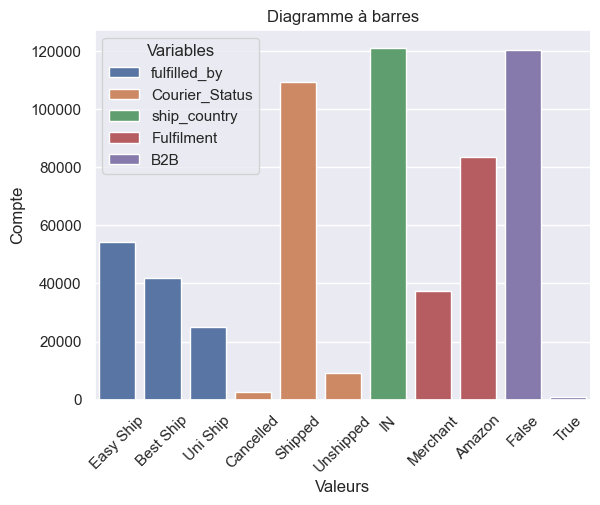

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
EDA = pd.read_csv('C:/Users/AS72180/OneDrive - ETS/Documents/ETS Hiver2024/ProjectMTI820/Modified_Amazon_Sale_Report.csv') 
melted_data = EDA[['fulfilled_by', 'Courier_Status', 'ship_country', 'Fulfilment', 'B2B']].melt()
# Diagramme à barres avec les trois variables
sns.countplot(x='value', hue='variable', data=melted_data)
plt.xlabel('Valeurs')
plt.ylabel('Compte')
plt.title('Diagramme à barres')
# Incliner les étiquettes de l'axe x à 45 degrés pour éviter le chevauchement
plt.xticks(rotation=45)
plt.legend(title='Variables')
plt.show()

C:\Users\AS72180\AppData\Local\Temp\ipykernel_1880\1543987145.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(y = 'Amount', x = 'Date', data = top10sales, aspect = 2,palette='turbo',kind="bar")


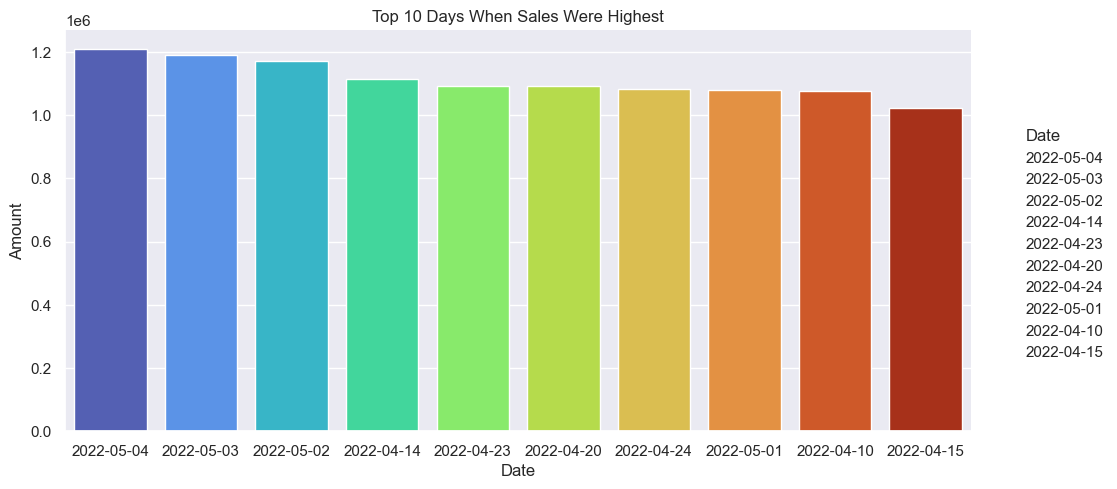

In [43]:
# set style
sns.set(style = 'darkgrid')
DaySalesInsights = EDA.copy()
DaySalesInsights['Date'] = pd.to_datetime(EDA['Date']).dt.date
top10sales = DaySalesInsights.groupby('Date').sum().sort_values('Amount', ascending = False)
top10sales = top10sales.reset_index().head(10)
sns.catplot(y = 'Amount', x = 'Date', data = top10sales, aspect = 2,palette='turbo',kind="bar")
plt.title('Top 10 Days When Sales Were Highest')
top10sales[['Amount']]
plt.show()

C:\Users\AS72180\AppData\Local\Temp\ipykernel_1880\959778123.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(y = 'Qty', x = 'Date', data = highqty, aspect = 2,palette='turbo',kind="bar")


,Qty
0,1889
1,1863
2,1805
3,1695
4,1694
5,1664
6,1661
7,1628
8,1619
9,1619


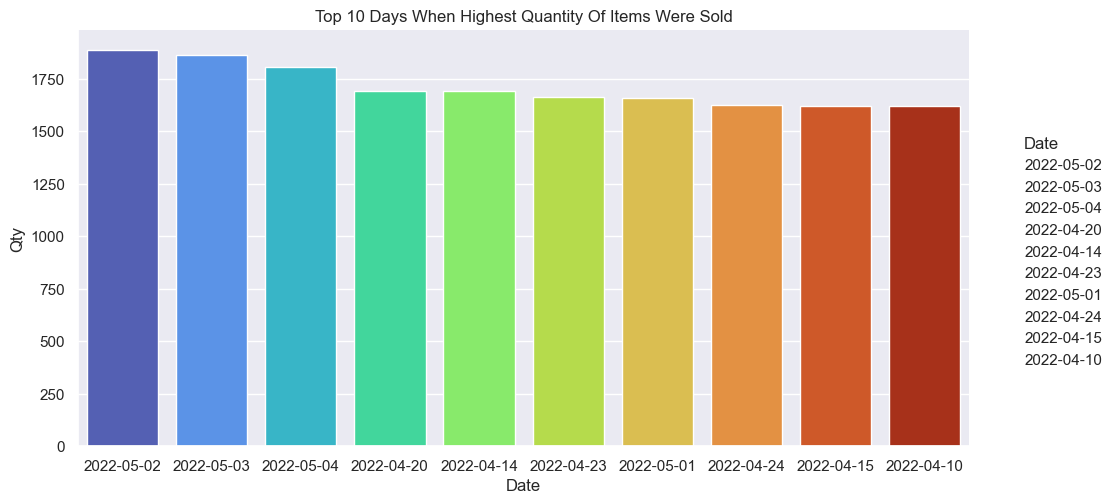

In [45]:
highqty = DaySalesInsights.groupby('Date').sum().sort_values('Qty', ascending = False)
highqty = highqty.reset_index().head(10)
sns.catplot(y = 'Qty', x = 'Date', data = highqty, aspect = 2,palette='turbo',kind="bar")
plt.title('Top 10 Days When Highest Quantity Of Items Were Sold')
highqty[['Qty']]

In [23]:
# 3. Load Data
# Connect to the target destination ( Azure SQL database)

In [24]:
""" import pyodbc
import csv

# Define your Azure SQL Database connection details
server = 'serversalemti820.database.windows.net'
database = 'sqldb-sales'
username = 'adminmti820'
password = 'MTI820@2024'
driver = '{ODBC Driver 18 for SQL Server}'

# Establish a connection to the database
conn = pyodbc.connect('DRIVER='+driver+';SERVER='+server+';DATABASE='+database+';UID='+username+';PWD='+ password)

# Create a cursor object to execute SQL queries
cursor = conn.cursor()

# Define the table creation query
create_table_query = """
# CREATE TABLE Sales (
#     Order_ID NVARCHAR(255),
#     Date DATE,
#     Status NVARCHAR(255),
#     Fulfilment NVARCHAR(255),
#     Sales_Channel NVARCHAR(255),
#     ship_service_level NVARCHAR(255),
#     Style NVARCHAR(255),
#     SKU NVARCHAR(255),
#     Category NVARCHAR(255),
#     Size NVARCHAR(255),
#     ASIN NVARCHAR(255),
#     CourierStatus NVARCHAR(255),
#     Qty INT,
#     Currency NVARCHAR(255),
#     Amount FLOAT,
#     ship_city NVARCHAR(255),
#     ship_state NVARCHAR(255),
#     ship_postal_code NVARCHAR(255),
#     ship_country NVARCHAR(255), 
#     promotion_ids NVARCHAR(255),
#     B2B BIT,
#     fulfilled_by NVARCHAR(255)
#)
"""

# Drop the table if it exists
cursor.execute("DROP TABLE IF EXISTS Sales")

# Create the table
cursor.execute(create_table_query)

# Commit the transaction
conn.commit()

# Path to your CSV file
csv_file = 'C:/Users/AS72180/OneDrive - ETS/Documents/ETS Hiver2024/ProjectMTI820/Modified_Amazon_Sale_Report.csv'
# Open the CSV file and read its contents
with open(csv_file, 'r') as file:
    reader = csv.reader(file)
    next(reader)  # Skip the header row if it exists
    for row in reader:
        # Insert each row into the database
        cursor.execute("INSERT INTO Sales (Order_ID, Date, Status, Fulfilment, Sales_Channel, ship_service_level, Style, SKU, Category, Size, ASIN, CourierStatus, Qty, Currency, Amount, ship_city, ship_state, ship_postal_code, ship_country, promotion_ids, B2B, fulfilled_by) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)", row)

# Commit the transaction
conn.commit()

# Close the cursor and connection
cursor.close()
conn.close()

print("Data imported successfully.") """

Data imported successfully.
